<a href="https://colab.research.google.com/github/khojiakbar05/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Menu Detector")

Menu Detector


In [ ]:
# --------------------
# Import Libraries
# --------------------
from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Define Dataset Path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print('Dataset_path: ', DATASET_PATH)


CUSTOM_CLASS_MAPPING = {    # label grouping | class consolidation
    'hamburger': 'hamburger',
    'hot_dog': 'hot_dog',
    #'dessert': 'dessert',
    'cheesecake': 'dessert',
    'cheese_plate': 'dessert',
    'chocolate_cake': 'dessert',
    'pizza': 'pizza'
}


CLASSES = ['hamburger', 'hot_dog', 'dessert', 'cheesecake', 'cheese_plate', 'chocolate_cake', 'pizza']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print(CLASS_TO_IDX)

transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],        # rangler 1-255
                               std=[0.229, 0.224, 0.225])  # rangler 0-1h
])

# 0 ~ 255
# 0.0 ~ 1.0
# H, W, C => C, H, W | RGB = Red, Green, Blue
# Normalize
# pixel = (pixel - mean) / std

Dataset_path:  /content/drive/MyDrive/food101_dataset
7
{'hamburger': 0, 'hot_dog': 1, 'dessert': 2, 'cheesecake': 3, 'cheese_plate': 4, 'chocolate_cake': 5, 'pizza': 6}


Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

In [ ]:
# ---------------------------
# Custom Dataset Class
# ---------------------------

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]
        try:
            image = Image.open(img_path)
            if image.mode == "P" or image.mode == "RGBA": # png | gif | RGBA
                image = image.convert("RGBA").convert("RGB")
            else:
                image = image.convert("RGB")
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            # Prevent infinite loop if all images are broken
            return self.__getitem__((idx + 1) % len(self.images))

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
 # -----------------------
# Gather and Split Data
# -----------------------

all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)
    print('class_path: ', class_path)
    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue
    for img in os.listdir(class_path):
        if img.lower().endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(class_path, img)
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

if len(all_images) == 0:
    print("No images found! Please verify your DATASET_PATH and folder structure.")
else:
    np.random.shuffle(all_images)
    split = int(0.8 * len(all_images))
    train_data = all_images[:split]
    val_data = all_images[split:]

    train_images, train_labels = zip(*train_data)
    val_images, val_labels = zip(*val_data)

    print('all_images:', len(all_images))

    dataset = FoodDataset(train_images, train_labels)
    print('len(dataset):', len(dataset))
    img, lbl = dataset[0]
    print('Sample image successfully loaded. Label index:', lbl)

class_path:  /content/drive/MyDrive/food101_dataset/hamburger
class_path:  /content/drive/MyDrive/food101_dataset/hot_dog
class_path:  /content/drive/MyDrive/food101_dataset/cheesecake
class_path:  /content/drive/MyDrive/food101_dataset/cheese_plate
class_path:  /content/drive/MyDrive/food101_dataset/chocolate_cake
class_path:  /content/drive/MyDrive/food101_dataset/pizza
all_images: 6000
len(dataset): 4800
Sample image successfully loaded. Label index: 6


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)  # thread | parallel loading for speed
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

In [ ]:
# pretraid model

model = mobilenet_v2(weights="IMAGENET1K_V1") # pretraid model | CNN | 1000 class | million
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES) # fine-tuning | freeze

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 130MB/s]


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device: ', device)

# Fallback initialization in case the model definition cell was not run
try:
    model = model.to(device)
except NameError:
    print("Model was not defined. Initializing model...")
    model = mobilenet_v2(weights="IMAGENET1K_V1")
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    model = model.to(device)

device:  cuda


In [ ]:
criterion = nn.CrossEntropyLoss()                     # Loss Function | 70% burger, '30% pilaf
optimizer = optim.Adam(model.parameters(), lr=0.0001) # weight
torch.backends.cudnn.benchmark = True                 # Benchmark settin | trick | 10%v20%

print('criterion: ', criterion)
print('optimizer: ', optimizer)

criterion:  CrossEntropyLoss()
optimizer:  Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [13]:
# --------------------
# Training Loop
# --------------------

NUM_EPOCHS = 10
best_accuracy = 0.0

for epoch in range(NUM_EPOCHS):
  model.train() # training mode
  running_loss = 0.0 # 70% | 30% Loss | 100%
  for images, labels in train_loader: # Forward and Backward(Backpropagation)
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad() # zero the gradient
    output = model(images) # Forward Pass
    loss = criterion(output, labels) # Calculate Loss (Fixed typo from outputs to output)
    loss.backward()
    optimizer.step() # Adam Optimizer
    running_loss += loss.item() # Track Loss

  # Validation (Moved inside the epoch loop)
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      _, predicted = torch.max(outputs, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

  val_acc = 100 * correct / total # Calculate validation accuracy
  print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] Loss: {running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

  if val_acc > best_accuracy:
    best_accuracy = val_acc
    torch.save(model.state_dict(), '/content/menu_detector.pth')
    print("Saved new best model!")

Epoch [1/10] Loss: 0.2373, Val Accuracy: 94.67%
Saved new best model!
Epoch [2/10] Loss: 0.0883, Val Accuracy: 94.08%
Epoch [3/10] Loss: 0.0403, Val Accuracy: 94.17%
Epoch [4/10] Loss: 0.0238, Val Accuracy: 94.92%
Saved new best model!
Epoch [5/10] Loss: 0.0113, Val Accuracy: 94.08%
Epoch [6/10] Loss: 0.0192, Val Accuracy: 93.50%
Epoch [7/10] Loss: 0.0246, Val Accuracy: 93.67%
Epoch [8/10] Loss: 0.0180, Val Accuracy: 94.33%
Epoch [9/10] Loss: 0.0195, Val Accuracy: 92.42%
Epoch [10/10] Loss: 0.0183, Val Accuracy: 93.67%


# menu_detector model usage

device:  cuda
Upload one or more images of hamburrger or hot dog: 


Saving 25331.jpg to 25331.jpg


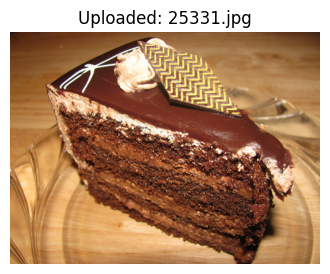

Prediction: 
dessert: 99.96%
pizza: 0.02%
hamburger: 0.01%
cheese_plate: 0.01%


In [14]:
# ----------------------
# Required Imports
# ---------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt



# ---------------------------
# Define Semantic Classes
# ---------------------------

CLASSES = ['hamburger', 'hot_dog', 'dessert', 'cheesecake', 'cheese_plate', 'chocolate_cake', 'pizza'] # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}



# ------------------------------------------------------
# Transform for Uploaded Images (no augmentation)
# ------------------------------------------------------

transform = transforms.Compose([
  transforms.Resize((224, 224)),
  transforms.ToTensor(),
  transforms.Normalize(mean=[0.485, 0.456, 0.406],
                       std=[0.229, 0.224, 0.225])
])


# ------------------------------------------------------
# Load Model
# ------------------------------------------------------

model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device: ', device)
model = model.to(device)
model.eval()



# ------------------------------------------------------
# Upload & Predict
# ------------------------------------------------------

print("Upload one or more images of hamburrger or hot dog: ")
uploaded = files.upload()

for image_name in uploaded.keys():
  image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')


  # Dispplay image
  plt.figure(figsize=(4, 4))
  plt.imshow(image)
  plt.axis('off')
  plt.title(f'Uploaded: {image_name}')
  plt.show()

  # Predict
  image_tensor = transform(image).unsqueeze(0).to(device)
  with torch.no_grad():
    output = model(image_tensor)
    probs = torch.softmax(output, dim=1)[0]
    topk = torch.topk(probs, 4)

  print("Prediction: ")
  for i in range(topk.indices.size(0)):
    label = CLASSES[topk.indices[i]]
    confidence = topk.values[i] * 100
    print(f"{label}: {confidence:.2f}%")